<a href="https://colab.research.google.com/github/Izaias02/-ATV04PW2/blob/main/analises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# 1. CARREGANDO OS PACOTES PARA A CAMADA GOLD / ANALYTICS
# ============================================================
library(googledrive)
library(readr)
library(dplyr)
library(ggplot2)

cat("✅ Pacotes carregados e prontos para a análise estatística do SBC!\n")

✅ Pacotes carregados e prontos para a análise estatística do SBC!


In [ ]:
# ============================================================
# 2. IDENTIFICAÇÃO E ENTRADA DA BASE TRATADA (SILVER -> GOLD)
# ============================================================

nome_pasta_aluno <- "Izaias"
pasta_aula       <- "Aula 6 - 31/08/2026"

cat("🔍 Buscando o arquivo limpo 'hospitais_leitos_sp_2025_silver.csv' no Google Drive...\n")

arquivo_silver_id <- drive_find(pattern = "hospitais_leitos_sp_2025_silver.csv", n_max = 1)

if (nrow(arquivo_silver_id) > 0) {
  cat("✅ Arquivo Silver localizado! ID de Rede:", arquivo_silver_id$id, "\n")

  drive_download(
    file = as_id(arquivo_silver_id$id),
    path = "/content/hospitais_leitos_sp_2025_silver.csv",
    overwrite = TRUE
  )

  df_saude_gold <- read_csv(
    "/content/hospitais_leitos_sp_2025_silver.csv",
    locale = locale(encoding = "UTF-8"),
    show_col_types = FALSE
  )

  cat("\n🎉 SUCESSO! Base carregada na Camada Gold com", nrow(df_saude_gold), "linhas únicas.\n")

} else {
  cat("❌ ERRO: O arquivo limpo da Silver não foi encontrado no seu Drive.\n")
}

🔍 Buscando o arquivo limpo 'hospitais_leitos_sp_2025_silver.csv' no Google Drive...


Is it OK to cache OAuth access credentials in the folder ~/.cache/gargle
between R sessions?
1: Yes
2: No


In [ ]:
# ============================================================
# 3. ENGENHARIA DE INDICADORES AVANÇADOS E AGREGAÇÃO MUNICIPAL
# ============================================================

df_municipios_analise <- df_saude_gold |>
  group_by(municipio) |>
  summarise(
    total_estabelecimentos   = n(),
    total_leitos_geral       = sum(leitos_existentes, na.rm = TRUE),
    total_leitos_sus         = sum(leitos_sus, na.rm = TRUE),
    total_uti_geral          = sum(uti_total_existente, na.rm = TRUE),
    total_uti_sus            = sum(uti_total_sus, na.rm = TRUE),

    # Indicador 1: Percentual de leitos privados (não SUS)
    pct_leitos_privados      = ((total_leitos_geral - total_leitos_sus) / total_leitos_geral) * 100,

    # Indicador 2: Razão de UTIs SUS sobre o total
    proporcao_uti_sus        = (total_uti_sus / total_uti_geral) * 100
  ) |>
  filter(total_leitos_geral > 0)

# Substituição de NAs e NaNs decorrentes de divisões por zero
df_municipios_analise[is.na(df_municipios_analise)] <- 0

# Adicionando o percentual real de cobertura SUS
df_municipios_analise$pct_leitos_sus <- 100 - df_municipios_analise$pct_leitos_privados

cat("=== 🚨 TOP 5 MUNICÍPIOS COM MENOR DISPONIBILIDADE RELATIVA DE LEITOS SUS ===\n")
df_municipios_analise |>
  arrange(desc(pct_leitos_privados)) |>
  select(municipio, total_leitos_geral, total_leitos_sus, pct_leitos_privados) |>
  head(5) |>
  print()

=== 🚨 TOP 5 MUNICÍPIOS COM MENOR DISPONIBILIDADE RELATIVA DE LEITOS SUS ===
# A tibble: 5 × 4
  municipio              total_leitos_geral total_leitos_sus pct_leitos_privados
  <chr>                               <dbl>            <dbl>               <dbl>
1 ARACOIABA DA SERRA                     45                0                 100
2 CEDRAL                                 60                0                 100
3 SANTA LUCIA                             8                0                 100
4 TREMEMBE                               12                0                 100
5 VARGEM GRANDE PAULISTA                 40                0                 100


In [ ]:
# ============================================================
# 4. CÁLCULO DOS PARÂMETROS ESTATÍSTICOS DA BASE
# ============================================================

materia_media     <- mean(df_saude_gold$leitos_existentes, na.rm = TRUE)
materia_mediana   <- median(df_saude_gold$leitos_existentes, na.rm = TRUE)
materia_variancia <- var(df_saude_gold$leitos_existentes, na.rm = TRUE)
materia_desvio    <- sd(df_saude_gold$leitos_existentes, na.rm = TRUE)

q1   <- quantile(df_saude_gold$leitos_existentes, 0.25, na.rm = TRUE)
q3   <- quantile(df_saude_gold$leitos_existentes, 0.75, na.rm = TRUE)
iqr  <- q3 - q1
cerca_superior <- q3 + (1.5 * iqr)

cat("\n=== 📊 PARÂMETROS DA BASE DE CONHECIMENTO (GOLD) ===\n")
cat("Média de Leitos por Hospital: ", round(materia_media, 2), "\n")
cat("Mediana de Leitos (Centro Real): ", materia_mediana, "\n")
cat("Variância dos Dados: ", round(materia_variancia, 2), "\n")
cat("Desvio Padrão (Afastamento): ", round(materia_desvio, 2), "\n")
cat("--------------------------------------------------\n")
cat("Primeiro Quartil (Q1): ", q1, "\n")
cat("Terceiro Quartil (Q3): ", q3, "\n")
cat("Intervalo Interquartil (IQR): ", iqr, "\n")
cat("Linha de Corte para Outlier (Cerca Superior): ", cerca_superior, "\n")


=== 📊 PARÂMETROS DA BASE DE CONHECIMENTO (GOLD) ===
Média de Leitos por Hospital:  107.16 
Mediana de Leitos (Centro Real):  68 
Variância dos Dados:  16678.55 
Desvio Padrão (Afastamento):  129.15 
--------------------------------------------------
Primeiro Quartil (Q1):  31 
Terceiro Quartil (Q3):  139.5 
Intervalo Interquartil (IQR):  108.5 
Linha de Corte para Outlier (Cerca Superior):  302.25 


In [ ]:
# ============================================================
# 5. GERAÇÃO E SALVAMENTO DOS GRÁFICOS PARA ANALYTICS
# ============================================================

# 5.1 Boxplot de Capacidade de Leitos
png("/content/boxplot_leitos_sp.png", width = 800, height = 600)
boxplot(df_saude_gold$leitos_existentes,
        main = "Distribuição da Capacidade de Leitos Hospitalares (SP)",
        ylab = "Quantidade de Leitos Existentes",
        col = "lightblue",
        border = "darkblue",
        outcol = "red",
        outpch = 16)
dev.off()

# 5.2 Gráfico de Dispersão: Assimetria de Oferta Pública
png("/content/dispersao_gargalo_sus.png", width = 800, height = 600)
plot(df_municipios_analise$total_leitos_geral, df_municipios_analise$total_leitos_sus,
     main = "Gargalo de Saúde: Leitos Totais vs. Disponibilidade SUS",
     xlab = "Total de Leitos Existentes no Município",
     ylab = "Leitos Disponíveis para o SUS",
     col = "darkgreen", pch = 16, log = "xy")
abline(a = 0, b = 1, col = "red", lty = 2, lwd = 2)
legend("topleft", legend = c("Municípios (SP)", "Cobertura SUS Ideal (100%)"),
       col = c("darkgreen", "red"), pch = c(16, NA), lty = c(NA, 2))
dev.off()

# 5.3 Histograma de Dependência do SUS
png("/content/histograma_cobertura_sus.png", width = 800, height = 600)
hist(df_municipios_analise$pct_leitos_sus,
     breaks = 20,
     main = "Distribuição dos Municípios por Nível de Atendimento SUS",
     xlab = "Percentual de Leitos Disponíveis para o SUS (%)",
     ylab = "Quantidade de Municípios (Frequência)",
     col = "lightblue",
     border = "darkblue")
abline(v = mean(df_municipios_analise$pct_leitos_sus), col = "red", lwd = 2, lty = 2)
legend("topleft", legend = c("Distribuição", "Média de Cobertura Estatal"),
       col = c("lightblue", "red"), lty = c(1, 2), lwd = c(5, 2))
dev.off()

cat("✅ Gráficos exportados com sucesso para o ambiente local!\n")

agg_record_338252f650f 
                     2

Warning message in xy.coords(x, y, xlabel, ylabel, log):
“5 y values <= 0 omitted from logarithmic plot”


agg_record_338252f650f 
                     2

agg_record_338252f650f 
                     2

✅ Gráficos exportados com sucesso para o ambiente local!


In [ ]:
# ============================================================
# 6. EXPORTAÇÃO DOS DADOS E GRÁFICOS PARA O GOOGLE DRIVE
# ============================================================

# 6.1 Salva a tabela tratada/agregada localmente em CSV
write_csv(df_municipios_analise, "/content/hospitais_leitos_sp_2025_analise.csv")

cat("🚀 Enviando a base consolidada e os gráficos para o Google Drive...\n")

# Procura ou define a pasta de destino no Google Drive
pasta_destino <- drive_find(pattern = pasta_aula, type = "folder", n_max = 1)

if (nrow(pasta_destino) > 0) {
  # Upload do Data Mart consolidado
  drive_upload(
    media = "/content/hospitais_leitos_sp_2025_analise.csv",
    path = as_id(pasta_destino$id),
    name = "hospitais_leitos_sp_2025_analise.csv",
    overwrite = TRUE
  )

  # Upload dos gráficos
  drive_upload(media = "/content/boxplot_leitos_sp.png", path = as_id(pasta_destino$id), overwrite = TRUE)
  drive_upload(media = "/content/dispersao_gargalo_sus.png", path = as_id(pasta_destino$id), overwrite = TRUE)
  drive_upload(media = "/content/histograma_cobertura_sus.png", path = as_id(pasta_destino$id), overwrite = TRUE)

  cat("\n🎉 Todos os artefatos de análise foram salvos com sucesso no Google Drive!\n")
} else {
  cat("⚠️ Pasta de destino não encontrada no Google Drive. Verifique a variável 'pasta_aula'.\n")
}

🚀 Enviando a base consolidada e os gráficos para o Google Drive...


Local file:

• /content/hospitais_leitos_sp_2025_analise.csv

Uploaded into Drive file:

• hospitais_leitos_sp_2025_analise.csv <id: 1TsJFXPRsfSuCFPymANvOaZumD4h5aiDF>

With MIME type:

• text/csv

Local file:

• /content/boxplot_leitos_sp.png

Uploaded into Drive file:

• boxplot_leitos_sp.png <id: 1S0uRIspKHCjzAFqGrFqMaaBEUJuo5qcT>

With MIME type:

• image/png

Local file:

• /content/dispersao_gargalo_sus.png

Uploaded into Drive file:

• dispersao_gargalo_sus.png <id: 1pHhjbd1ChjbueyC-JZZ4iHLfEaIF3Aup>

With MIME type:

• image/png

Local file:

• /content/histograma_cobertura_sus.png

Uploaded into Drive file:

• histograma_cobertura_sus.png <id: 1xsUz8xFOIz-oGP0Yy_clCZDS-FDDcQGH>

With MIME type:

• image/png




🎉 Todos os artefatos de análise foram salvos com sucesso no Google Drive!


=== 📊 DISTRIBUIÇÃO DOS ALERTAS GERADOS PELO SBC ===
# A tibble: 3 × 4
  alerta_sbc                  n percentual rotulo     
  <chr>                   <int>      <dbl> <chr>      
1 Macro Polo de Saúde        58       16.5 58 (16.5%) 
2 Suficiência Regulada      289       82.1 289 (82.1%)
3 Vazio Sanitário Público     5        1.4 5 (1.4%)   


Local file:

• /content/distribuicao_alertas_sbc.png

Uploaded into Drive file:

• distribuicao_alertas_sbc.png <id: 1OOBk9rJrlqvOGBCgbQUK9w9EHjtR_MmP>

With MIME type:

• image/png

Local file:

• /content/hospitais_leitos_sp_2025_gold_alertas.csv

Uploaded into Drive file:

• hospitais_leitos_sp_2025_gold_alertas.csv
  <id: 1nvVsFxIPtfjX0bQu_ll-OTNyU-npDngQ>

With MIME type:

• text/csv

Local file:

• /content/regras_se_entao.csv

Uploaded into Drive file:

• regras_se_entao.csv <id: 1R0bVsZ_hOnO43InjqqRjbtA2IW3ho6Be>

With MIME type:

• text/csv




🎉 Gráfico e arquivos de regras salvos com sucesso no Google Drive!


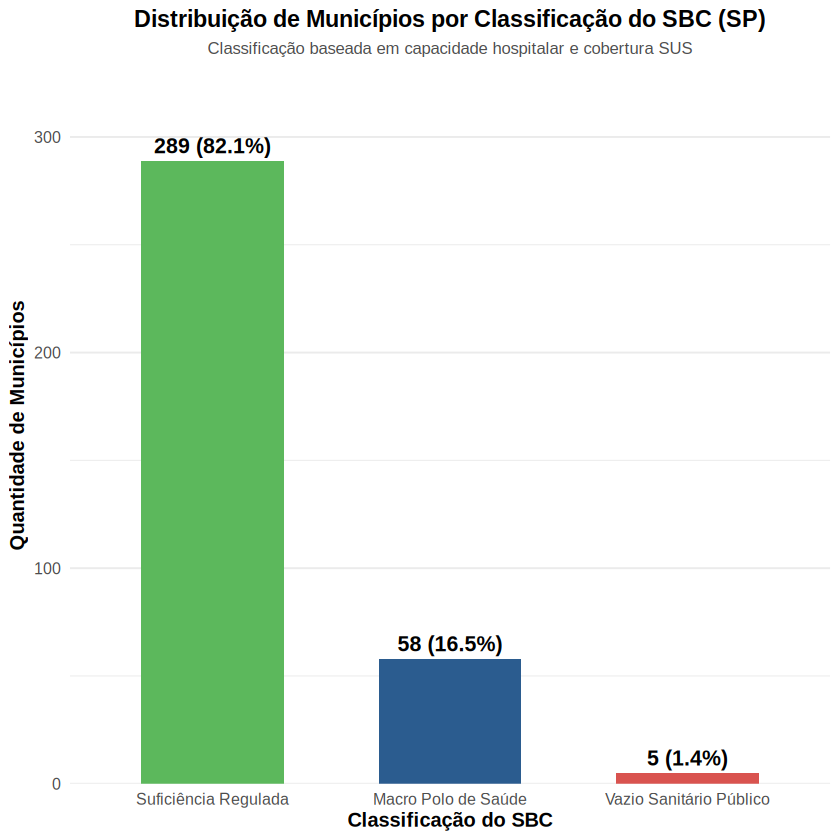

In [ ]:
# ============================================================
# 7. APLICAÇÃO DAS REGRAS DO SBC E GERAÇÃO DO GRÁFICO DE ALERTAS
# ============================================================

library(dplyr)
library(ggplot2)
library(googledrive)

# 7.1 Aplicação da lógica de inferência (SE, E, ENTÃO)
df_municipios_analise <- df_municipios_analise %>%
  mutate(
    alerta_sbc = case_when(
      total_leitos_geral > cerca_superior ~ "Macro Polo de Saúde",
      pct_leitos_privados == 100 ~ "Vazio Sanitário Público",
      TRUE ~ "Suficiência Regulada"
    )
  )

# 7.2 Tabela de distribuição dos alertas
df_distribuicao_alertas <- df_municipios_analise %>%
  count(alerta_sbc) %>%
  mutate(
    percentual = round((n / sum(n)) * 100, 1),
    rotulo = paste0(n, " (", percentual, "%)")
  )

cat("=== 📊 DISTRIBUIÇÃO DOS ALERTAS GERADOS PELO SBC ===\n")
print(df_distribuicao_alertas)

# 7.3 Construção do Gráfico de Barras com ggplot2
grafico_alertas <- ggplot(df_distribuicao_alertas, aes(x = reorder(alerta_sbc, -n), y = n, fill = alerta_sbc)) +
  geom_bar(stat = "identity", width = 0.6, show.legend = FALSE) +
  geom_text(aes(label = rotulo), vjust = -0.5, fontface = "bold", size = 4.5) +
  scale_fill_manual(values = c(
    "Macro Polo de Saúde" = "#2b5c8f",
    "Vazio Sanitário Público" = "#d9534f",
    "Suficiência Regulada" = "#5cb85c"
  )) +
  labs(
    title = "Distribuição de Municípios por Classificação do SBC (SP)",
    subtitle = "Classificação baseada em capacidade hospitalar e cobertura SUS",
    x = "Classificação do SBC",
    y = "Quantidade de Municípios"
  ) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", size = 14, hjust = 0.5),
    plot.subtitle = element_text(size = 10, hjust = 0.5, color = "gray30"),
    axis.title = element_text(face = "bold"),
    panel.grid.major.x = element_blank()
  )

# Exibir o gráfico no notebook
print(grafico_alertas)

# 7.4 Salvando o gráfico localmente
ggsave(
  filename = "/content/distribuicao_alertas_sbc.png",
  plot = grafico_alertas,
  width = 8,
  height = 6,
  dpi = 300
)

# 7.5 Exportação do gráfico e do CSV com a nova coluna para o Google Drive
write_csv(df_municipios_analise, "/content/hospitais_leitos_sp_2025_gold_alertas.csv")

# Criando também o arquivo de texto com a matriz de regras para a pasta 3-gold
regras_texto <- data.frame(
  id_regra = c("R1", "R2", "R3"),
  condicao_se = c(
    paste0("total_leitos_geral > ", round(cerca_superior, 2)),
    "pct_leitos_privados == 100",
    "Outros casos"
  ),
  classificacao_entao = c(
    "Macro Polo de Saúde",
    "Vazio Sanitário Público",
    "Suficiência Regulada"
  )
)
write_csv(regras_texto, "/content/regras_se_entao.csv")

# Envio dos arquivos para o Google Drive
pasta_destino <- drive_find(pattern = pasta_aula, type = "folder", n_max = 1)

if (nrow(pasta_destino) > 0) {
  drive_upload(media = "/content/distribuicao_alertas_sbc.png", path = as_id(pasta_destino$id), overwrite = TRUE)
  drive_upload(media = "/content/hospitais_leitos_sp_2025_gold_alertas.csv", path = as_id(pasta_destino$id), overwrite = TRUE)
  drive_upload(media = "/content/regras_se_entao.csv", path = as_id(pasta_destino$id), overwrite = TRUE)
  cat("\n🎉 Gráfico e arquivos de regras salvos com sucesso no Google Drive!\n")
}

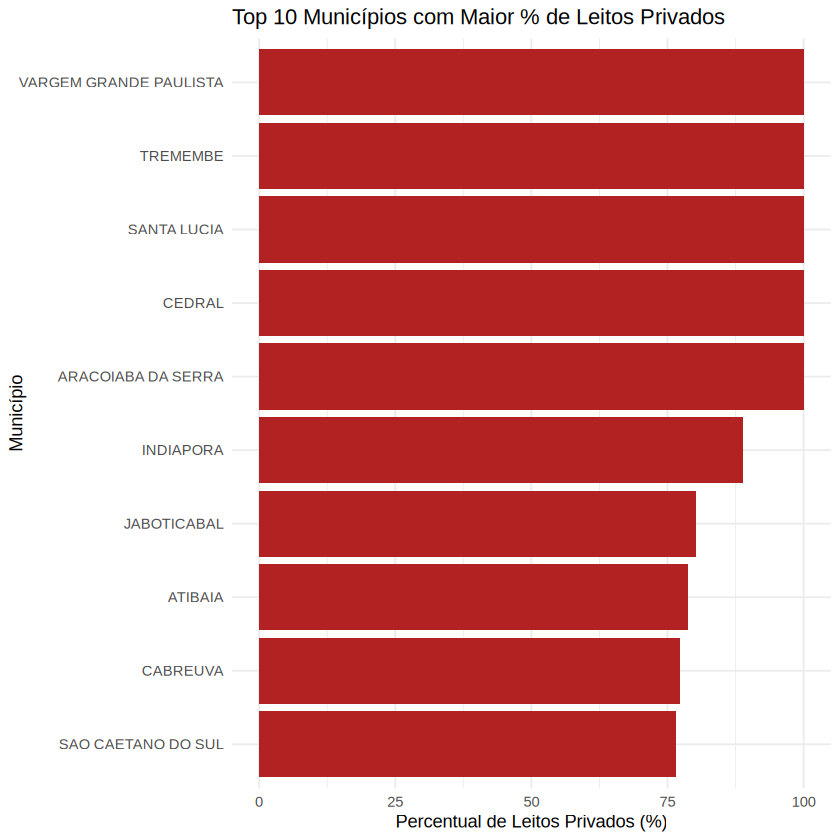

In [ ]:
# Visualização dos municípios com maior presença privada
ggplot(head(arrange(df_municipios_analise, desc(pct_leitos_privados)), 10),
       aes(x = reorder(municipio, pct_leitos_privados), y = pct_leitos_privados)) +
  geom_col(fill = "firebrick") +
  coord_flip() +
  labs(
    title = "Top 10 Municípios com Maior % de Leitos Privados",
    x = "Município",
    y = "Percentual de Leitos Privados (%)"
  ) +
  theme_minimal()

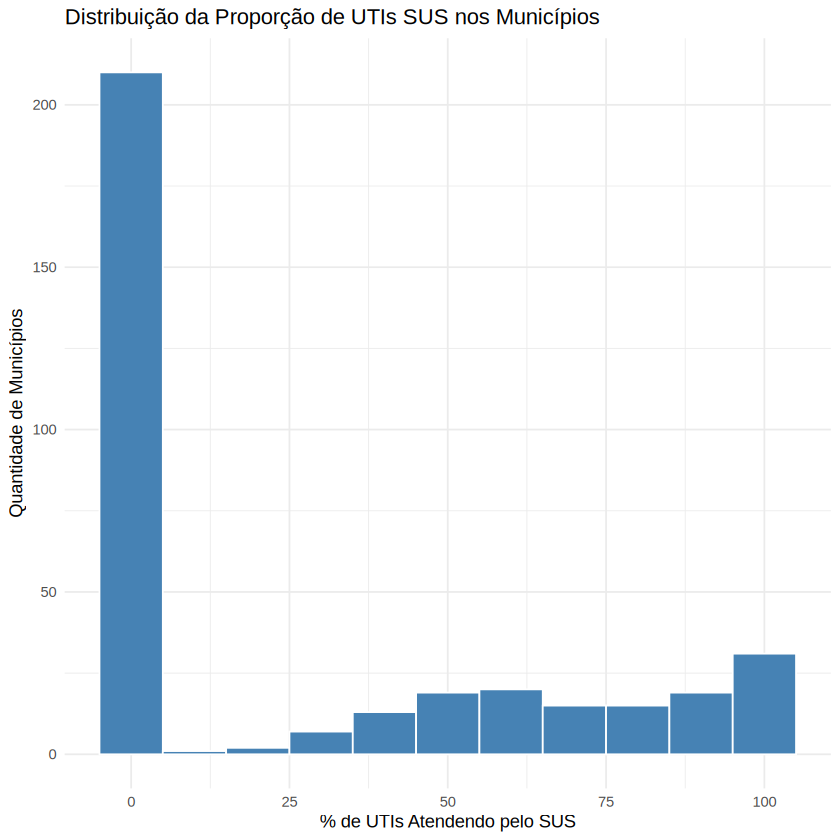

In [ ]:
# Distribuição da proporção de UTIs SUS nos municípios
ggplot(df_municipios_analise, aes(x = proporcao_uti_sus)) +
  geom_histogram(binwidth = 10, fill = "steelblue", color = "white") +
  labs(
    title = "Distribuição da Proporção de UTIs SUS nos Municípios",
    x = "% de UTIs Atendendo pelo SUS",
    y = "Quantidade de Municípios"
  ) +
  theme_minimal()

`geom_smooth()` using formula = 'y ~ x'


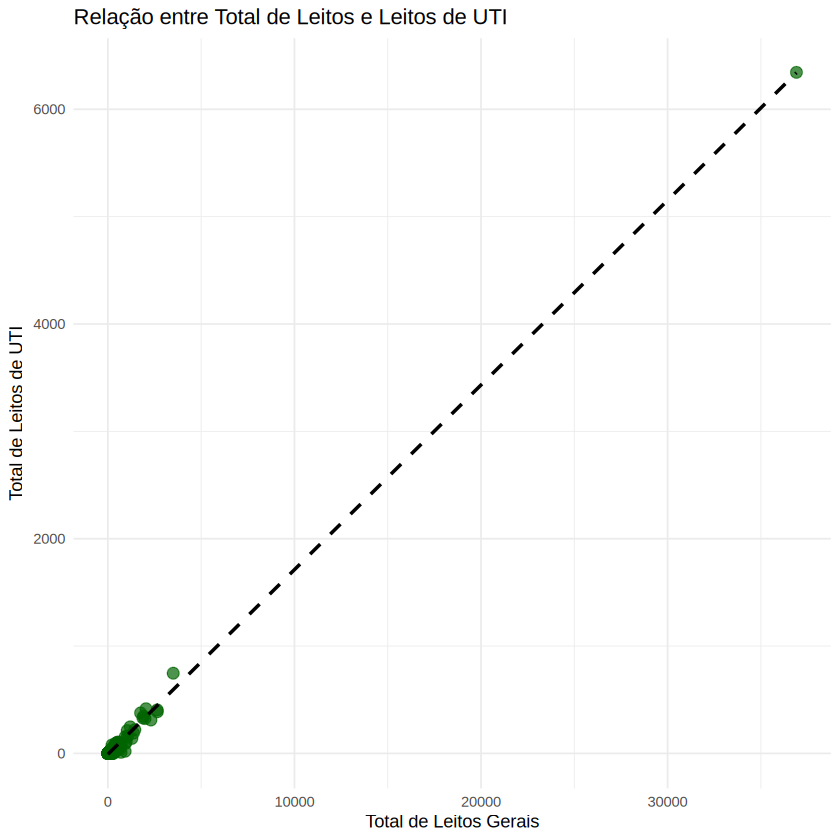

In [ ]:
# Relação entre total de leitos e total de UTIs por município
ggplot(df_municipios_analise, aes(x = total_leitos_geral, y = total_uti_geral)) +
  geom_point(color = "darkgreen", alpha = 0.7, size = 3) +
  geom_smooth(method = "lm", se = FALSE, color = "black", linetype = "dashed") +
  labs(
    title = "Relação entre Total de Leitos e Leitos de UTI",
    x = "Total de Leitos Gerais",
    y = "Total de Leitos de UTI"
  ) +
  theme_minimal()